# Sesión 13 · Notebook de clase · Visualizaciones efectivas

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 7 · Unidad 3, tema 3.6: qué gráfico para qué pregunta, ejes y escalas honestas, color con intención, texto que ayuda, menos es más, seaborn y contar una historia con datos.

Desde la sesión 10 sabemos **dibujar** histogramas, cajas, barras, dispersiones y líneas. Hoy la pregunta es otra: ¿el gráfico **comunica**? Un gráfico efectivo responde una pregunta, se entiende sin que nadie lo explique, no engaña con los ejes ni con el color y dice en el título lo que hay que ver. Es lo que van a necesitar las figuras del **informe de la Entrega 1** (sesión 14) y el pitch final.

Datos, en la carpeta `datos/`: `ventas_completo.csv` (260 ventas, S9), `cosechas.csv` (480 ciclos, S10), `entregas.csv` (420 entregas, Taller 3) y `ventas_diarias.csv` (720 días, S12).

**Cómo trabajar con este notebook**
- Ejecute las celdas en orden. En los ejercicios **Su turno**, reemplace los `...`; la celda `assert` siguiente comprueba el resultado.
- Las reglas de la sesión 10 siguen: todo gráfico lleva título y etiquetas con unidad. Hoy se añaden las demás.

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from matplotlib.patches import Rectangle

v = pd.read_csv("datos/ventas_completo.csv", parse_dates=["fecha"])
c = pd.read_csv("datos/cosechas.csv", parse_dates=["fecha_siembra"])
e = pd.read_csv("datos/entregas.csv", parse_dates=["fecha"])
vd = pd.read_csv("datos/ventas_diarias.csv", parse_dates=["fecha"]).set_index("fecha").sort_index()
SLATE, DARK, LIGHT, RED, YELLOW = "#768B9E", "#2F3E4E", "#C9D3DC", "#B4483C", "#E0B400"

def titulo_de(ax):
    # el título del eje, esté centrado o a la izquierda (loc="left")
    return ax.get_title() or ax.get_title(loc="left") or ax.get_title(loc="right")

print("ventas:", v.shape, "| cosechas:", c.shape, "| entregas:", e.shape, "| ventas diarias:", vd.shape)

ventas: (260, 13) | cosechas: (480, 13) | entregas: (420, 9) | ventas diarias: (720, 3)


## 1. Qué gráfico para qué pregunta

El gráfico se elige por la **pregunta**, no por el gusto. Los seis del curso cubren casi todo:

| Pregunta | Gráfico | Ejemplo |
| :-- | :-- | :-- |
| ¿cuánto vale cada **categoría**? (comparar) | **barras** (ordenadas; horizontales si los nombres son largos) | ingreso por categoría |
| ¿cómo se **distribuye** una variable? | **histograma** (o diagrama de caja) | tiempo de entrega |
| ¿la distribución **cambia según el grupo**? | **cajas** por grupo | costo por tipo de servicio |
| ¿**x se relaciona con y**? | **dispersión** | peso y precio del camarón |
| ¿cómo **cambia con el tiempo**? | **líneas** | ingreso mensual |
| ¿cómo se **reparte** un total entre partes? | **barras apiladas al 100 %** (nunca pastel) | método de pago por ciudad |

Un gráfico, **un mensaje**: si hay que decir dos cosas, son dos gráficos (o un panel).

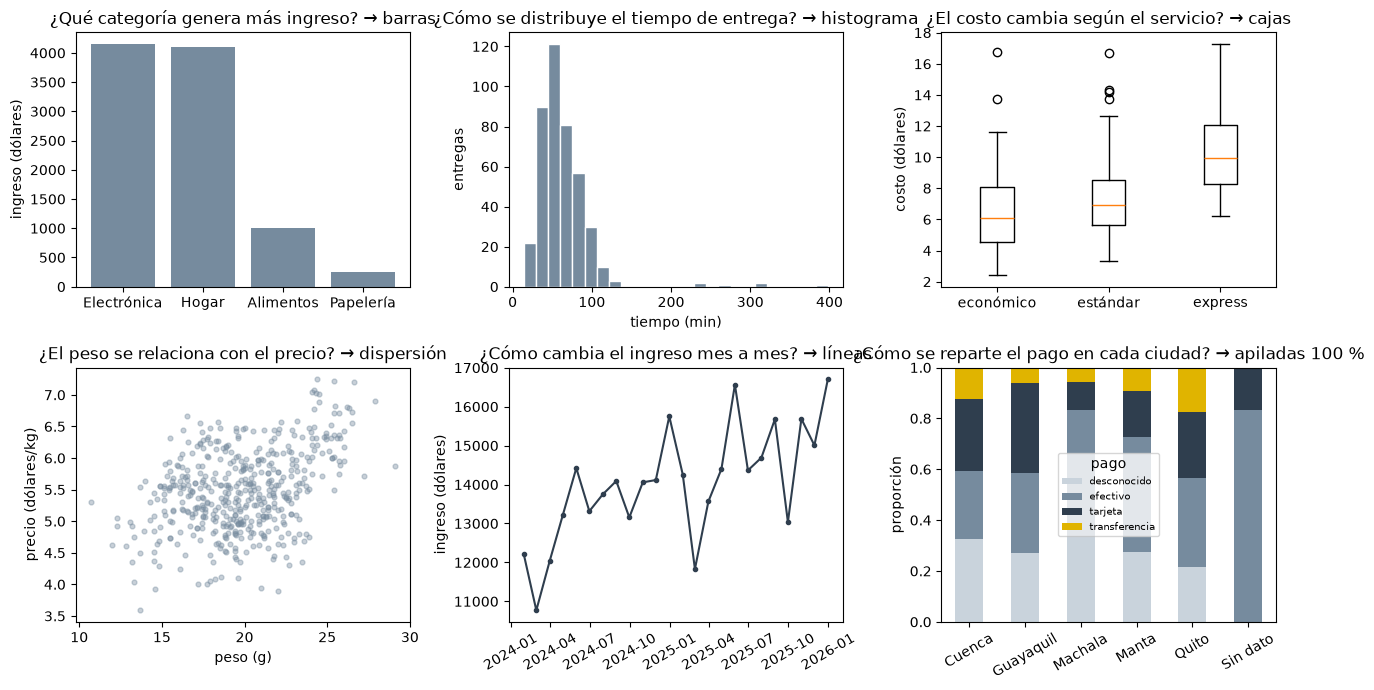

In [22]:
# Los seis gráficos del curso, cada uno con su pregunta
fig, axes = plt.subplots(2, 3, figsize=(13, 7))  # 2 filas, 3 columnas

a = axes.flat  # axes no será una matriz, será un arreglo

# comparar categorías: barras ordenadas
ing_cat = v.groupby("categoria")["ingreso"].sum().sort_values(ascending=False)
a[0].bar(ing_cat.index, ing_cat, color=SLATE)
a[0].set_title("¿Qué categoría genera más ingreso? → barras")
a[0].set_ylabel("ingreso (dólares)")

# distribución: histograma
a[1].hist(e["tiempo_min"], bins=25, color=SLATE, edgecolor="white")
a[1].set_title("¿Cómo se distribuye el tiempo de entrega? → histograma")
a[1].set_xlabel("tiempo (min)")
a[1].set_ylabel("entregas")

# distribución por grupo: cajas
grupos = [e.loc[e["tipo_servicio"] == s, "costo"] for s in ["económico", "estándar", "express"]]
a[2].boxplot(grupos) # múltiples boxplot pero con matplotlib y no pandas
a[2].set_xticks([1, 2, 3], ["económico", "estándar", "express"])
a[2].set_title("¿El costo cambia según el servicio? → cajas")
a[2].set_ylabel("costo (dólares)")

# relación: dispersión
a[3].scatter(c["peso_g"], c["precio_kg"], alpha=0.4, s=12, color=SLATE) 
a[3].set_title("¿El peso se relaciona con el precio? → dispersión")
a[3].set_xlabel("peso (g)")
a[3].set_ylabel("precio (dólares/kg)")

# tiempo: líneas
mensual = vd["ingreso"].resample("ME").sum()
a[4].plot(mensual.index, mensual, color=DARK, marker="o", markersize=3)
a[4].set_title("¿Cómo cambia el ingreso mes a mes? → líneas")
a[4].set_ylabel("ingreso (dólares)")
a[4].tick_params(axis="x", rotation=30)

# composición: barras apiladas al 100 %
comp = pd.crosstab(v["ciudad"], v["metodo_pago"], normalize="index")
comp.plot.bar(stacked=True, ax=a[5], color=[LIGHT, SLATE, DARK, YELLOW])
a[5].set_title("¿Cómo se reparte el pago en cada ciudad? → apiladas 100 %")
a[5].set_ylabel("proporción")
a[5].set_xlabel("")
a[5].legend(fontsize=7, title="pago")
a[5].tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

### Su turno 1.1 · 4 min
Para cada pregunta, escriba en el diccionario `eleccion` el gráfico que la responde, con una de estas palabras exactas: `"barras"`, `"histograma"`, `"cajas"`, `"dispersion"`, `"lineas"`, `"apiladas"`.

- **a**: ¿Cuántas entregas hizo cada ciudad en julio y agosto?
- **b**: ¿Cómo cambió el número de siembras mes a mes en 2024 y 2025?
- **c**: ¿Los ciclos más largos dan camarones más pesados?
- **d**: ¿Qué forma tiene la distribución del peso de los paquetes?
- **e**: ¿La calificación de las entregas difiere entre tipos de servicio?
- **f**: ¿Qué parte de las ventas de cada categoría se paga en efectivo?

In [ ]:
# TODO: reemplace los ... por su código
eleccion = {"a": ..., "b": ..., "c": ..., "d": ..., "e": ..., "f": ...}

In [ ]:
assert eleccion == {"a": "barras", "b": "lineas", "c": "dispersion", "d": "histograma", "e": "cajas", "f": "apiladas"}, "comparar → barras; tiempo → líneas; relación → dispersión; distribución → histograma; distribución por grupo → cajas; reparto → apiladas"
print("Correcto. La pregunta elige el gráfico: comparar, distribuir, relacionar, cambiar en el tiempo, repartir.")

## 2. Ejes y escalas honestas

El mismo dato puede parecer una diferencia enorme o ninguna según el eje. Cuatro reglas:

1. Las **barras empiezan en cero**: la altura *es* el valor; un eje cortado (`ylim` que no parte de 0) exagera diferencias pequeñas. Las **líneas** pueden no empezar en cero (lo que importa es la variación), pero entonces el eje se lee con cuidado.
2. **Paneles comparables, misma escala** (`sharey=True`, `sharex=True`): si cada panel tiene su eje, no se pueden comparar.
3. Valores que abarcan **varios órdenes de magnitud** (de 2 000 a 146 000): escala **logarítmica** (`ax.set_xscale("log")`), y se dice en la etiqueta.
4. La **proporción** del gráfico (alto / ancho) cambia la pendiente aparente: una línea casi plana en un gráfico ancho parece empinada en uno alto. Use proporciones razonables (4:3, 16:9) y la misma para gráficos que se comparan.

In [ ]:
# Regla 1: el mismo dato con eje cortado y con eje desde cero. Guayaquil vendió 9.3 % más que Quito, no cuatro veces más
ing_ciudad = v.groupby("ciudad")["ingreso"].sum().loc[["Guayaquil", "Quito"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (titulo, desde) in zip(axes, [("Eje cortado: parece 4 veces más", 3000), ("Eje desde cero: 9.3 % más", 0)]):
    ax.bar(ing_ciudad.index, ing_ciudad, color=SLATE)
    ax.set_ylim(desde, 3500)
    ax.set_title(titulo); ax.set_ylabel("ingreso (dólares)")
    for i, val in enumerate(ing_ciudad):
        ax.text(i, val + 20, f"{val:,.0f}", ha="center", fontsize=9)
fig.tight_layout()
plt.show()

In [ ]:
# Regla 2: paneles con y sin eje compartido
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, serv in zip(axes, ["económico", "estándar", "express"]):
    ax.hist(e.loc[e["tipo_servicio"] == serv, "costo"], bins=15, color=SLATE, edgecolor="white")
    ax.set_title(serv); ax.set_xlabel("costo (dólares)")
axes[0].set_ylabel("entregas")
fig.suptitle("Con sharey=True se ve que express cuesta más y es menos frecuente; con ejes libres cada panel parecería igual", fontsize=10)
fig.tight_layout()
plt.show()

In [ ]:
# Regla 3: cosecha_kg va de 2 658 a 146 286 kg: en escala lineal casi todo se apila a la izquierda; en log se ve la forma
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(c["cosecha_kg"], bins=30, color=SLATE, edgecolor="white"); axes[0].set_title("Escala lineal: la piscina de 52 ha aplasta al resto")
bins_log = np.logspace(np.log10(c["cosecha_kg"].min()), np.log10(c["cosecha_kg"].max()), 30)
axes[1].hist(c["cosecha_kg"], bins=bins_log, color=SLATE, edgecolor="white"); axes[1].set_xscale("log"); axes[1].set_title("Escala logarítmica: se ve la distribución completa")
for ax in axes:
    ax.set_xlabel("cosecha (kg; eje logarítmico en el panel derecho)"); ax.set_ylabel("ciclos")
fig.tight_layout()
plt.show()

### Su turno 2.1 · 4 min
El gráfico de abajo compara el peso promedio del camarón por zona con el eje cortado en 19,3 g: parece que **Guayas** produce camarón mucho más grande, pero la diferencia real entre la zona más alta y la más baja es de **2.8 %**. Arréglelo: eje desde cero (`ax.set_ylim(0, ...)`), el valor encima de cada barra con un decimal y un título que diga la conclusión real.

In [ ]:
# TODO: reemplace los ... por su código
peso_zona = c.groupby("zona")["peso_g"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(peso_zona.index, peso_zona, color=SLATE)
ax.set_ylim(19.3, 20.1)                 # <- el eje cortado que exagera
ax.set_title("Peso por zona")           # <- un título que no dice nada
ax.set_ylabel("peso promedio (g)")
plt.show()

In [ ]:
assert ax.get_ylim()[0] == 0, "las barras empiezan en cero: ax.set_ylim(0, ...)"
assert len(ax.texts) >= 5, "el valor encima de cada barra (ax.text en un bucle)"
assert titulo_de(ax) not in ("", "Peso por zona"), "el título dice la conclusión (que el peso casi no cambia entre zonas)"
print("Correcto: con el eje desde cero la conclusión cambia: el peso no depende de la zona.")

## 3. Color con intención

El color es un **mensaje**, no decoración. Reglas:

- **Un color para todo, y otro para lo que importa**: la barra o la línea del hallazgo en oscuro, el resto en gris. Más de 3 o 4 colores en un gráfico ya no se distinguen.
- **Paleta según la variable**: categorías sin orden → colores distintos (paleta **categórica**); categorías ordenadas (pequeña, mediana, grande) → del claro al oscuro (paleta **secuencial**); valores alrededor de un centro (correlación de −1 a 1) → dos colores con blanco en medio (paleta **divergente**, como el mapa de calor de la sesión 11).
- **Daltonismo** (1 de cada 12 hombres): nunca rojo frente a verde como única diferencia; use claro/oscuro, azul/naranja, o la paleta `"colorblind"` de seaborn.
- El **mismo color significa lo mismo** en todas las figuras del informe (Guayaquil siempre del mismo color).

In [ ]:
# Destacar una: la categoría que responde la pregunta, en oscuro; el resto en gris
ing_cat = v.groupby("categoria")["ingreso"].sum().sort_values(ascending=False)
colores = [DARK if cat == "Hogar" else LIGHT for cat in ing_cat.index]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(ing_cat.index, ing_cat, color=colores)
ax.set_title("Hogar genera casi tanto ingreso como Electrónica con menos ventas")
ax.set_ylabel("ingreso (dólares)"); ax.set_xlabel("categoría")
plt.show()

In [ ]:
# Paleta secuencial para una variable ordenada (tamaño: pequeña < mediana < grande)
tam = v.groupby("tamano")["ingreso"].mean().reindex(["pequeña", "mediana", "grande"])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(tam.index, tam, color=[LIGHT, SLATE, DARK])          # del claro al oscuro: el orden se ve sin leer
ax.set_title("El ticket promedio crece con el tamaño del producto")
ax.set_ylabel("ingreso promedio por venta (dólares)"); ax.set_xlabel("tamaño")
plt.show()

In [ ]:
# Paletas de seaborn: categórica apta para daltónicos, secuencial y divergente
import seaborn as sns
fig, axes = plt.subplots(3, 1, figsize=(7, 2.4))
for ax, (nombre, pal) in zip(axes, [("colorblind (categórica)", sns.color_palette("colorblind", 6)),
                                    ("Blues (secuencial)", sns.color_palette("Blues", 6)),
                                    ("RdBu_r (divergente)", sns.color_palette("RdBu_r", 6))]):
    for i, col in enumerate(pal):
        ax.bar(i, 1, color=col, width=0.9)
    ax.set_title(nombre, fontsize=9, loc="left"); ax.set_axis_off()
fig.tight_layout()
plt.show()

### Su turno 3.1 · 4 min
Dibuje el **porcentaje de ventas por ciudad** (`v["ciudad"]`, `value_counts(normalize=True) * 100`, ordenado de mayor a menor) como barras, con **Guayaquil en oscuro** (`DARK`) y el resto en gris claro (`LIGHT`), el porcentaje encima de cada barra y un título con la conclusión (Guayaquil concentra el 36.9 % de las ventas).

In [ ]:
# TODO: reemplace los ... por su código
pct_ciudad = (v["ciudad"].value_counts(normalize=True) * 100).round(1)
colores = [... for ciudad in pct_ciudad.index]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(pct_ciudad.index, pct_ciudad, color=colores)
for i, val in enumerate(pct_ciudad):
    ax.text(...)
ax.set_title(...)
ax.set_ylabel(...)
ax.set_xlabel(...)
plt.show()

In [ ]:
assert len(ax.patches) == 6 and len({to_hex(p.get_facecolor()) for p in ax.patches}) == 2 and to_hex(ax.patches[0].get_facecolor()) == DARK.lower(), "dos colores: DARK para Guayaquil (la primera barra), LIGHT para el resto"
assert len(ax.texts) >= 6 and titulo_de(ax) != "" and ax.get_ylabel() != "", "porcentaje encima de cada barra, título y etiquetas"
print("Correcto: un solo color destacado dirige la mirada a la respuesta.")

## 4. Texto que ayuda: el título dice la conclusión

Lo que más mejora un gráfico no es el color: es el **texto**.

- El **título es la conclusión**: «El sábado vende el doble que el domingo», no «Ingreso por día de la semana». Lo que describe las variables va en los ejes o en un subtítulo (`ax.set_title(..., loc="left")` para la conclusión y `ax.text` o `fig.suptitle` para el subtítulo).
- **Etiquetas con unidad** en los ejes (regla desde la sesión 10) y los **valores sobre las barras** cuando importan (`ax.bar_label(barras, fmt="%.0f")`).
- **Etiquetas directas** en vez de leyenda: el nombre de cada línea al final de la línea (`ax.text`); la leyenda obliga a ir y volver.
- **Una anotación** para el punto clave (`ax.annotate` con flecha): el pico, el cambio, el dato raro.
- Sin cajas alrededor de la leyenda (`frameon=False`) ni títulos en mayúsculas.

In [ ]:
# Antes / después: el mismo gráfico con texto que describe y con texto que concluye
por_dia = vd.groupby(vd.index.dayofweek)["ingreso"].mean()
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(DIAS, por_dia, color=SLATE)
axes[0].set_title("Ingreso por día de la semana"); axes[0].set_ylabel("ingreso")
barras = axes[1].bar(DIAS, por_dia, color=[LIGHT] * 5 + [DARK, LIGHT])
axes[1].bar_label(barras, fmt="%.0f", fontsize=8, padding=2)
axes[1].set_title("El sábado vende casi el doble que el domingo", loc="left", fontweight="bold")
axes[1].text(0, 1.02, "ingreso promedio por día, 2024-2025", transform=axes[1].transAxes, fontsize=9, color="gray")
axes[1].set_ylabel("ingreso promedio (dólares por día)"); axes[1].set_xlabel("día de la semana")
axes[1].annotate("el día más flojo", xy=(6, por_dia.iloc[6]), xytext=(4.6, 560), arrowprops=dict(arrowstyle="->", color=RED), color=RED, fontsize=9)
fig.tight_layout()
plt.show()

In [ ]:
# Etiquetas directas en vez de leyenda: una línea por año, con el año al final de cada línea
tabla_mes = vd.pivot_table(index=vd.index.month, columns=vd.index.year, values="ingreso", aggfunc="sum")
fig, ax = plt.subplots(figsize=(8, 3.8))
for anio, color in zip(tabla_mes.columns, [LIGHT, DARK]):
    ax.plot(tabla_mes.index, tabla_mes[anio], marker="o", color=color, linewidth=2)
    ax.text(12.2, tabla_mes[anio].iloc[-1], str(anio), color=color, va="center", fontweight="bold")   # el nombre al final de la línea
ax.set_xticks(range(1, 13)); ax.set_xlim(0.5, 13)
ax.set_title("2025 supera a 2024 en 11 de los 12 meses; la forma del año se repite", loc="left")
ax.set_xlabel("mes"); ax.set_ylabel("ingreso mensual (dólares)")
plt.show()

### Su turno 4.1 · 4 min
Dibuje la **mediana del tiempo de entrega por ciudad** (`e`, `groupby("ciudad")["tiempo_min"].median()`, ordenada) como barras con el valor encima (`ax.bar_label`), un **título que diga la conclusión** (qué ciudad tarda más y cuánto) y una **anotación** con flecha sobre la ciudad más lenta.

In [ ]:
# TODO: reemplace los ... por su código
t_ciudad = e.groupby("ciudad")["tiempo_min"].median().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
barras = ax.bar(t_ciudad.index, t_ciudad, color=SLATE)
ax.bar_label(...)
ax.annotate(..., xy=(0, t_ciudad.iloc[0]), xytext=(1.5, t_ciudad.iloc[0] + 8), arrowprops=dict(arrowstyle="->"))
ax.set_title(...)
ax.set_ylabel(...)
ax.set_xlabel(...)
ax.set_ylim(0, t_ciudad.max() + 15)
plt.show()

In [ ]:
assert len(ax.containers) >= 1 and any(len(getattr(cont, "datavalues", [])) == len(t_ciudad) for cont in ax.containers), "ax.bar_label(barras, fmt=...)"
assert len(ax.texts) >= len(t_ciudad) + 1, "los valores encima (bar_label) y una anotación (annotate)"
assert titulo_de(ax) not in ("", "Tiempo por ciudad"), "el título dice la conclusión"
print("Correcto: título que concluye, valores encima y la ciudad más lenta señalada.")

## 5. Menos es más: quitar lo que no informa

Todo lo que no es dato compite con el dato (*chartjunk*): fondos, bordes, cuadrículas pesadas, 3D, marcos de leyenda, demasiadas marcas, decimales de más. Quitar:

- los bordes superior y derecho (`ax.spines["top"].set_visible(False)`), la cuadrícula a una ligera (`ax.grid(axis="y", alpha=0.3)`) y detrás de las barras (`ax.set_axisbelow(True)`);
- las categorías que no caben: las 8 más frecuentes y «otras» (sesión 9, `map`);
- las barras desordenadas: **ordenar** por valor (salvo que la categoría tenga orden propio: meses, tallas);
- el *spaghetti*: cinco líneas que se cruzan → **pequeños múltiplos** (`subplots` con `sharey`), o una línea destacada y el resto en gris.

Como las mismas tres líneas se repiten en cada gráfico, se escriben una vez en una **función** `estilo(ax)` y se llama siempre.

In [ ]:
def estilo(ax):
    """Limpieza estándar de un gráfico del informe: sin bordes de arriba y derecha, cuadrícula ligera detrás."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

# Antes: cuadrícula pesada, bordes, colores de más, barras sin orden. Después: estilo(ax), orden, un color
ing_ciudad = v.groupby("ciudad")["ingreso"].sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(ing_ciudad.index, ing_ciudad, color=["red", "green", "blue", "orange", "purple", "brown"])
axes[0].grid(True, color="black"); axes[0].set_title("ANTES: INGRESO POR CIUDAD"); axes[0].tick_params(axis="x", rotation=45)
orden = ing_ciudad.sort_values(ascending=False)
axes[1].bar(orden.index, orden, color=SLATE); estilo(axes[1])
axes[1].set_title("Después: Guayaquil y Quito suman dos tercios del ingreso", loc="left")
axes[1].set_ylabel("ingreso (dólares)"); axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

In [ ]:
# Spaghetti -> pequeños múltiplos: entregas por semana en cada ciudad (sin la primera y la última semana, incompletas)
sem_ciudad = e.groupby([pd.Grouper(key="fecha", freq="W"), "ciudad"]).size().unstack(fill_value=0).iloc[1:-1]
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8), sharey=True)
for ax, ciudad in zip(axes, sem_ciudad.columns):
    ax.plot(sem_ciudad.index, sem_ciudad[ciudad], color=DARK, marker="o", markersize=3)
    ax.set_title(ciudad, fontsize=10); ax.tick_params(axis="x", rotation=60, labelsize=7); estilo(ax)
axes[0].set_ylabel("entregas por semana")
fig.suptitle("Guayaquil nunca baja de 15 entregas por semana; Quito oscila entre 8 y 20; las otras tres no pasan de 9", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

## 6. seaborn: menos código, estilo coherente

**seaborn** está construido sobre matplotlib (viene con Anaconda). Da un estilo limpio con una línea (`sns.set_theme(style="whitegrid")`), dibuja directamente desde un DataFrame (`data=`, `x=`, `y=`, `hue=`) y hace en una llamada lo que en matplotlib son varias (barras por grupo, cajas por grupo, líneas por categoría, paneles por una columna con `catplot`/`relplot`). A cambio, menos control fino; como devuelve un `ax`, lo de matplotlib (título, etiquetas, `estilo`) sigue aplicándose. **Las reglas no cambian**: título con la conclusión y unidades.

In [ ]:
import seaborn as sns
sns.set_theme(style="whitegrid", palette="colorblind")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
sns.barplot(data=v, x="categoria", y="ingreso", estimator="sum", errorbar=None, color=SLATE, ax=axes[0])
axes[0].set_title("Ingreso por categoría (barplot)"); axes[0].set_ylabel("ingreso (dólares)")
sns.boxplot(data=e, x="tipo_servicio", y="costo", order=["económico", "estándar", "express"], color=LIGHT, ax=axes[1])
axes[1].set_title("Costo por servicio (boxplot)"); axes[1].set_ylabel("costo (dólares)")
tabla_larga = vd.groupby([vd.index.year.rename("anio"), vd.index.month.rename("mes")])["ingreso"].sum().reset_index()
sns.lineplot(data=tabla_larga, x="mes", y="ingreso", hue="anio", marker="o", palette=[LIGHT, DARK], ax=axes[2])
axes[2].set_title("Ingreso mensual por año (lineplot con hue)"); axes[2].set_ylabel("ingreso (dólares)")
fig.tight_layout()
plt.show()

In [ ]:
# Paneles por una columna en una sola llamada: catplot (cajas de costo por servicio, un panel por ciudad)
g = sns.catplot(data=e, x="tipo_servicio", y="costo", col="ciudad", kind="box", order=["económico", "estándar", "express"],
                col_wrap=5, height=2.8, aspect=0.9, color=LIGHT)
g.set_axis_labels("tipo de servicio", "costo (dólares)")
g.tick_params(axis="x", rotation=30)
g.figure.suptitle("El costo del servicio express es mayor en todas las ciudades", y=1.03)
plt.show()
sns.reset_orig()      # volver al estilo de matplotlib para el resto del notebook

## 7. Contar una historia con datos, y «Arregla este gráfico»

Un informe o un pitch no es una colección de gráficos: es una **historia** con tres partes, como en Resolución de Problemas:

1. **Contexto**: la pregunta y por qué importa (una frase).
2. **Hallazgo**: el gráfico, con el título que lo dice, y la **frase que lo acompaña** (un número y su lectura).
3. **Qué hacer**: la recomendación o la siguiente pregunta.

Orden: de lo general (cuánto, cómo se distribuye) a lo específico (qué grupo, cuándo, por qué). Cada gráfico, un mensaje. Y cada gráfico pasa la **prueba de los 5 segundos**: alguien que no sabe nada lo mira cinco segundos y dice lo mismo que el título.

### Arregla este gráfico

Tres gráficos malos. Cada celda `todo` trae el código que los produce: reescríbalo. Lo que se evalúa es lo de hoy: gráfico correcto, ejes honestos, color con intención, título que concluye, sin ruido.

### Su turno 7.1 · 5 min · El pastel
Ventas por ciudad en un pastel con seis porciones, leyenda aparte y porcentajes que no se pueden comparar. Rehágalo como **barras horizontales ordenadas** (`ax.barh`, de mayor a menor, la mayor arriba) con el número de ventas al final de cada barra, un título con la conclusión y `estilo(ax)`. Pista: con `barh`, `sort_values(ascending=True)` deja la mayor arriba.

In [ ]:
# TODO: reemplace los ... por su código
n_ciudad = v["ciudad"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.pie(n_ciudad, labels=None, autopct="%1.1f%%", startangle=90)
ax.legend(n_ciudad.index, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Gráfico 1")
plt.show()

In [ ]:
assert len(ax.patches) == 6 and all(isinstance(p, Rectangle) for p in ax.patches), "barras (barh), no pastel"
assert [p.get_width() for p in ax.patches] == sorted(p.get_width() for p in ax.patches), "ordenadas: la mayor arriba (sort_values(ascending=True) con barh)"
assert titulo_de(ax) not in ("", "Gráfico 1") and ax.get_xlabel() != "", "título con la conclusión y etiqueta con unidad"
print("Correcto: las barras ordenadas se comparan de un vistazo; el pastel, no.")

### Su turno 7.2 · 5 min · El eje cortado y el arcoíris
Peso promedio por zona con el eje cortado en 19,3 g, un color por barra sin motivo y el título «Gráfico 2». Rehágalo: eje desde cero, **un solo color** (o dos, si destaca una zona con motivo), valor encima de cada barra, título que diga que el peso **no depende de la zona** (2.8 % entre la mayor y la menor), `estilo(ax)`.

In [ ]:
# TODO: reemplace los ... por su código
peso_zona = c.groupby("zona")["peso_g"].mean()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(peso_zona.index, peso_zona, color=["red", "green", "blue", "orange", "purple"])
ax.set_ylim(19.3, 20.05)
ax.set_title("Gráfico 2")
ax.grid(True, color="black", linewidth=1.2)
plt.show()

In [ ]:
assert ax.get_ylim()[0] == 0 and len({to_hex(p.get_facecolor()) for p in ax.patches}) <= 2, "eje desde cero y uno o dos colores"
assert titulo_de(ax) not in ("", "Gráfico 2") and len(ax.texts) >= 5 and ax.get_ylabel() != "", "título con la conclusión, valores encima, unidad"
print("Correcto: eje honesto, un color, y el título dice lo que de verdad muestra el dato.")

### Su turno 7.3 · 5 min · El spaghetti
Entregas por semana en cinco ciudades: cinco líneas de colores que se cruzan, la leyenda tapa los datos y el título es «Gráfico 3». Rehágalo con **una ciudad destacada** (Guayaquil en `DARK`, grueso) y las otras cuatro en gris claro (`LIGHT`), el **nombre de cada ciudad al final de su línea** (`ax.text`) en vez de leyenda, título con la conclusión y `estilo(ax)`. Pista: recorra `sem_ciudad.columns` (la tabla de la sección 5) y elija color y grosor según la ciudad.

In [ ]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(8, 4))
for ciudad in sem_ciudad.columns:
    ax.plot(sem_ciudad.index, sem_ciudad[ciudad], label=ciudad, linewidth=2.5)
ax.legend(loc="center")
ax.set_title("Gráfico 3")
plt.show()

In [ ]:
assert len(ax.lines) == 5 and len({to_hex(l.get_color()) for l in ax.lines}) == 2, "cinco líneas, dos colores (una destacada, cuatro en gris)"
assert ax.get_legend() is None and len(ax.texts) >= 5, "sin leyenda: el nombre al final de cada línea con ax.text"
assert titulo_de(ax) not in ("", "Gráfico 3") and ax.get_ylabel() != "", "título con la conclusión y unidad"
print("Correcto: una línea destacada y etiquetas directas cuentan la historia sin leyenda.")

## 8. Las figuras del informe (Entrega 1)

El informe de la Entrega 1 lleva las figuras **fuera** del notebook: archivos PNG insertados en el documento. Reglas para que se lean bien impresas y en pantalla:

- `fig.savefig("figuras/fig03_ingreso_mensual.png", dpi=150, bbox_inches="tight")` **antes** de `plt.show()`; nombre con número y contenido.
- Tamaño pensado para la página: `figsize=(7, 3.5)` para una figura a lo ancho; `(10, 4)` para una serie larga. Letra legible al reducir (≥ 9 pt).
- Todas con el mismo estilo (`estilo(ax)`), los mismos colores para las mismas categorías, título que concluye.
- En el documento: **número** («Figura 3»), **pie de figura** (qué muestra, datos y unidad) y una **referencia en el texto** («como muestra la Figura 3, …»). Una figura que el texto no menciona, sobra.
- Tablas: pocas filas (≤ 8), redondeadas, con unidad en el encabezado; el detalle queda en el notebook.

In [ ]:
# Patrón para cada figura del informe: dibujar -> estilo -> guardar -> mostrar
os.makedirs("figuras", exist_ok=True)
mensual = vd["ingreso"].resample("ME").sum()
mm3 = mensual.rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(mensual.index, mensual, color=LIGHT, marker="o", markersize=3, label="ingreso mensual")
ax.plot(mm3.index, mm3, color=DARK, linewidth=2.2, label="media móvil de 3 meses")
ax.set_title("El ingreso mensual crece un 9 % en 2025 y repite la temporada: bajo en febrero, alto en mayo y diciembre", loc="left", fontsize=10)
ax.set_xlabel("mes"); ax.set_ylabel("ingreso (dólares)")
ax.legend(frameon=False)
estilo(ax)
fig.autofmt_xdate()
fig.savefig("figuras/fig_s13_ingreso_mensual.png", dpi=150, bbox_inches="tight")
plt.show()
print("guardada:", os.path.getsize("figuras/fig_s13_ingreso_mensual.png") // 1024, "KB")

### Su turno 8.1 · en casa (va a la Entrega 1)
Pase por el filtro de hoy las figuras de la Tarea 2 de su grupo (y la serie de tiempo de la sesión 12): gráfico correcto para la pregunta, eje desde cero, un color con intención, título que concluye, `estilo(ax)`, y guárdelas en `figuras/` con `dpi=150`. Al menos **cuatro** figuras del informe deben cumplir las reglas de esta sesión; la plantilla del informe (`Entrega1_Plantilla_Informe.docx`) tiene el lugar de cada una.

## 9. Errores frecuentes

| Síntoma | Causa | Solución |
| :-- | :-- | :-- |
| las diferencias parecen enormes | eje de las barras que no empieza en cero | `ax.set_ylim(0, ...)`; las barras siempre desde cero |
| dos paneles que «se ven iguales» aunque los datos difieren | cada panel con su propia escala | `sharey=True`, `sharex=True` |
| nadie distingue los colores | más de 4 colores, o rojo/verde | un color + uno destacado; paleta `colorblind`; claro/oscuro |
| el lector no sabe qué mirar | el título describe («Ingreso por mes») | el título concluye («Diciembre dobla a febrero») |
| la leyenda tapa el gráfico o queda lejos | `legend()` por defecto | etiquetas directas con `ax.text`; o `frameon=False` y `loc=` fuera del dato |
| la figura sale borrosa en el informe | `savefig` sin `dpi` o `show()` antes de guardar | `dpi=150`, `bbox_inches="tight"`, guardar antes de `plt.show()` |
| el texto de los ejes se monta | fechas o nombres largos | `fig.autofmt_xdate()`, `barh`, `rotation=30` |
| pastel con 6 porciones | reparto de un total | barras ordenadas (o apiladas al 100 % si se compara entre grupos) |
| `bar_label` da error | matplotlib antiguo (< 3.4) | actualice Anaconda o use `ax.text` en un bucle |
| seaborn cambia el estilo de todas las figuras | `set_theme` es global | `sns.reset_orig()` al terminar, o aplique el tema a todo el informe |

**Antes de la próxima sesión (S14, semana del 16 de noviembre):** se entrega la **Entrega 1** al inicio (informe PDF + notebook + datos + figuras), cada grupo presenta 5 minutos y después se rinde la **Lección 2** (integradora, Unidades 1–3, individual). El enunciado y las plantillas de la Entrega 1 están en el aula virtual. Lecturas: VanderPlas cap. 4, «Customizing Plot Legends», «Text and Annotation», «Customizing Ticks» y «Customizing Matplotlib»; McKinney §9.1, «Marcas, etiquetas y leyendas» y «Anotaciones y dibujos en un subgráfico» (lectura de la sesión 10).